In [4]:
import numpy as np
import json
import os
import sys
import matplotlib.pyplot as plt
import scienceplots  # optional, requires latex
plt.style.use(['science', 'grid'])
import jax
from jax import numpy as jnp

# Import plotting utility functions
sys.path.append('../')
from plot_util import (init_metrics, update_metrics, init_variables, update_variables,
                       plot_field, plot_field_residual, plot_field_columns, make_formatter, subsample_steps, pcolor_plot,
                        animate_frame, moving_average, moving_min)

In [12]:
# Select run to plot

results_folder = r"results"

measurments_type = ["displacement","strain"][0]
material_law = ["isotropic","orthotropic"][0]
dic_measurments = 0
iteration = 100000
time = 0
n_measurments = 36672 if dic_measurments else 100
noise = 0.0
dic_prefix = 'dic_' if dic_measurments else '' 
run_number = 0

run = f"{material_law}_{n_measurments}x{n_measurments}_{noise}noise_{time if time else iteration}{'min' if time else 'iter'}{f'-{run_number}' if run_number else ''}"
run_folder = os.path.join(results_folder, run)+"/"

In [13]:
# Load Configuration and Data

with open(os.path.join(run_folder, "config.json")) as f:
    run_config = json.load(f)

def read_data_file(filename):
    with open(filename, "r") as f:
        steps = []
        values = []
        for line in f.readlines():
            step, value = line.strip().split(' ', 1)
            steps.append(eval(step))
            values.append(eval(value))
    return steps, values

# Load loss and variable history data
loss_history = np.loadtxt(os.path.join(run_folder, "loss_history.dat"))
# loss_history_mean = moving_average(loss_history, 20)
# loss_history_min = moving_min(loss_history, 20)
variables_history = read_data_file(os.path.join(run_folder, "variables_history.dat"))

# Compute different metrics
residuals = loss_history[:, -1]
PDE_loss = np.mean(loss_history[:, 1:3], axis=1)
Mat_loss = np.mean(loss_history[:, 3:5], axis=1)
DIC_loss = np.mean(loss_history[:, 5:7], axis=1)
steps_loaded = loss_history[:, 0]

# Extract material parameters from config
E_init = run_config["problem"]["params_init"][0] / 1e3  # Convert to GPa: 1e3 N/mm^2 = 1 GPa
nu_init = run_config["problem"]["params_init"][1]
E_actual = run_config["problem"]["params_actual"][0] / 1e3  # Convert to GPa: 1e3 N/mm^2 = 1 GPa
nu_actual = run_config["problem"]["params_actual"][1]

E_history = np.array(variables_history[1])[:len(steps_loaded), 0] / 1e3  # in GPa (1e3 N/mm^2 = 1 GPa)
nu_history = np.array(variables_history[1])[:len(steps_loaded), 1]

E_name = r"$E$"
nu_name = r"$\nu$"

metrics = [residuals, PDE_loss, Mat_loss, DIC_loss]
metrics_names = ["Rel. l2 error", "PDE Loss", "Material Loss", "DIC Loss"]

# Configure x-axis based on iterations or elapsed time
step_type = "time"  # or "iteration"
time_unit = "min"   # or "s"
t_elapsed = run_config["execution"]["elapsed"]
if step_type == "time":
    steps = np.array(steps_loaded) * t_elapsed / steps_loaded[-1]
    if time_unit == "min":
        steps = steps / 60
else:
    steps = steps_loaded

Parameter      Initial        Final          Reference      Rel. Error (%) 
E (GPa)        100.00         0.49           52.00          99.064         
nu             0.2000         -0.0437        0.3000         114.578        


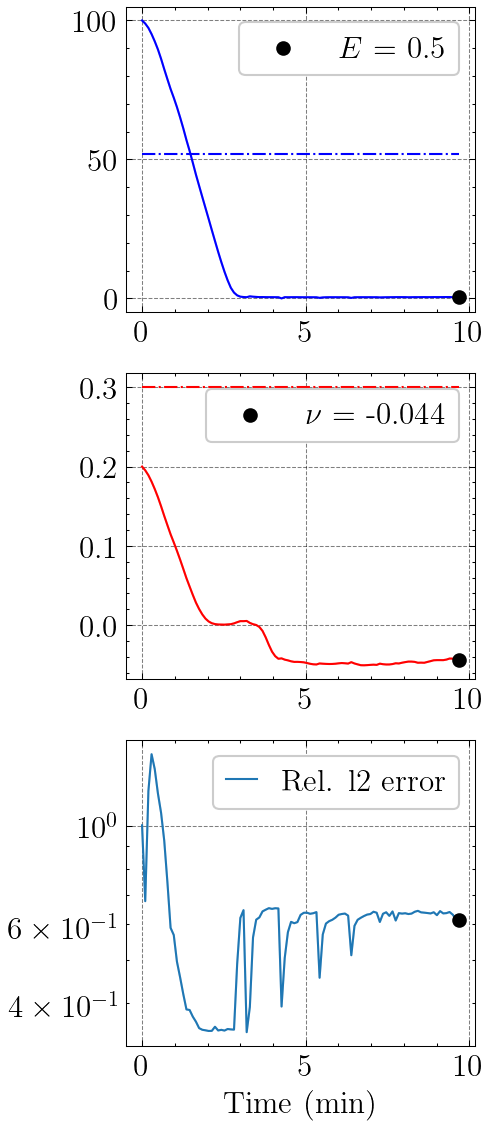

In [14]:
# Plot Metrics and Parameter Evolution

iteration = len(steps) - 1
# --- Plot Metrics ---
# fig, ax_metric = plt.subplots(1, 1, figsize=(3, 3), dpi=100)
# lines, scatters = init_metrics(ax_metric, steps, metrics, metrics_names, step_type=step_type, time_unit=time_unit, metrics_idx=[0])
# update_metrics(iter, lines, scatters, steps, metrics, metrics_idx=[0])
# plt.show()

# --- Plot Parameter Evolution ---
# fig, axs_vars = plt.subplots(2, 1, figsize=(3, 6), dpi=100)
# line_E, line_nu, scatter_E, scatter_nu, axs_vars = init_variables(
#     axs_vars, steps, E_actual, nu_actual, E_history, nu_history, E_name, nu_name)
# update_variables(iter, line_E, line_nu, scatter_E, scatter_nu,
#                  axs_vars, steps, E_history, nu_history, E_actual, nu_actual, E_name, nu_name)
# plt.show()

# --- Print Final Parameter Values ---
E_final = np.mean(E_history[-10:])
nu_final = np.mean(nu_history[-10:])
print(f"{'Parameter':<15}{'Initial':<15}{'Final':<15}{'Reference':<15}{'Rel. Error (%)':<15}")
print(f"{'E (GPa)':<15}{E_init:<15.2f}{E_final:<15.2f}{E_actual:<15.2f}{(abs(E_final - E_actual) / E_actual * 100):<15.3f}")
print(f"{'nu':<15}{nu_init:<15.4f}{nu_final:<15.4f}{nu_actual:<15.4f}{(abs(nu_final - nu_actual) / nu_actual * 100):<15.3f}")

# --- Combined Plot ---
fig, axs_combined = plt.subplots(3, 1, figsize=(3, 9), dpi=150)
lines, scatters = init_metrics(axs_combined[-1], steps, metrics, metrics_names, step_type=step_type, time_unit=time_unit, metrics_idx=[0])
update_metrics(iteration, lines, scatters, steps, metrics, metrics_idx=[0])
line_E, line_nu, scatter_E, scatter_nu, axs_vars = init_variables(
    axs_combined[:2], steps, E_actual, nu_actual, E_history, nu_history, E_name, nu_name)
update_variables(iteration, line_E, line_nu, scatter_E, scatter_nu,
                 axs_vars, steps, E_history, nu_history, E_actual, nu_actual, E_name, nu_name)
plt.show()

In [15]:
# Load Field Data
field_names = run_config["network"]["logged_fields"]
fields_loaded = [0, 1, 2, 3, 4, 5, 6, 7] # 0: ux, 1: uy, 2: exx, 3: eyy, 4: exy to be loaded

fields = [None] * 8
for fid in fields_loaded:
    field_name = field_names[fid]
    _, V_pinn = read_data_file(os.path.join(run_folder, f"{field_name}_history.dat"))
    fields[fid] = np.array(V_pinn)

In [16]:
import matplotlib.colors as mcolors
import matplotlib.transforms as mtransforms

def plot_field_columns(fig, ax, fields, fields_id, iteration,
                       Xmesh, Ymesh, Xgrid, Ygrid,
                       func, field_names, colormap, make_formatter):
    """
    Plot exact, computed, and residual fields (with colorbars) for each field.

    Parameters:
      - fig: matplotlib figure
      - ax: 2D array of axes with shape (3, 1+n_fields)
      - fields: list (or dict) of field data
      - fields_id: list of field ids to plot
      - iteration: current iteration index
      - Xmesh, Ymesh: meshgrid arrays for plotting (edges, n+1 x n+1)
      - Xgrid, Ygrid: meshgrid arrays for evaluation (centers, n x n)
      - func: function returning the exact field (used to compute field differences)
      - field_names: list of field names
      - colormap: colormap to use
      - make_formatter: function to create scalar formatter for colorbars

    Returns:
      (ims_ref, ims_field, ims_res)
    """
    ims_ref, ims_field, ims_res = [], [], []

    # Flatten evaluation grid for model calls
    eval_points = np.hstack((Xgrid.reshape(-1, 1), Ygrid.reshape(-1, 1)))
    fields_exact_all = func(eval_points).reshape(Xgrid.shape + (-1,))

    for i, field_id in enumerate(fields_id):
        # --- Exact solution (top row) ---
        ax_exact = ax[0][i]
        field_exact = fields_exact_all[..., field_id]
        field_norm = mcolors.Normalize(vmin=field_exact.min(), vmax=field_exact.max())
        im_ref = pcolor_plot(ax_exact, Xmesh, Ymesh, field_exact, field_names[field_id] + "_true",
                             colormap=colormap, norm=field_norm)
        ims_ref.append(im_ref)

        # Colorbar for exact
        pos = ax_exact.get_position()
        cax_pos = mtransforms.Bbox.from_bounds(pos.x0 + pos.width*0.05, pos.y1 + 0.04,
                                               pos.width*0.9, 0.01)
        cax = fig.add_axes(cax_pos)
        cbfield = fig.colorbar(im_ref, cax=cax, orientation='horizontal', format=make_formatter())
        cbfield.ax.xaxis.set_ticks_position('top')

        # --- Predicted field (middle row) ---
        ax_field = ax[1][i]
        field_pred = np.array(fields[field_id][iteration]).reshape(Xgrid.shape)
        im_field = pcolor_plot(ax_field, Xmesh, Ymesh, field_pred, field_names[field_id] + "_pred",
                               colormap=colormap, norm=field_norm)
        ims_field.append(im_field)

        # --- Residual (bottom row) ---
        ax_res = ax[2][i]
        field_diff = field_pred - field_exact
        diff_norm = mcolors.Normalize(vmin=-np.abs(field_diff).max(), vmax=np.abs(field_diff).max())
        im_res = pcolor_plot(ax_res, Xmesh, Ymesh, field_diff, field_names[field_id] + "_diff",
                             colormap='coolwarm', norm=diff_norm)
        ims_res.append(im_res)

        pos = ax_res.get_position()
        cax_pos = mtransforms.Bbox.from_bounds(pos.x0 + pos.width*0.05, pos.y0 - 0.03,
                                               pos.width*0.9, 0.01)
        cax = fig.add_axes(cax_pos)
        fig.colorbar(im_res, cax=cax, orientation='horizontal', format=make_formatter())

    return ims_ref, ims_field, ims_res


Fig width: 18.0, set it to 6.00 < 6.34 (A4 with margins) in latex to have a printed font size of 6 for titles and 5.00 for the axis


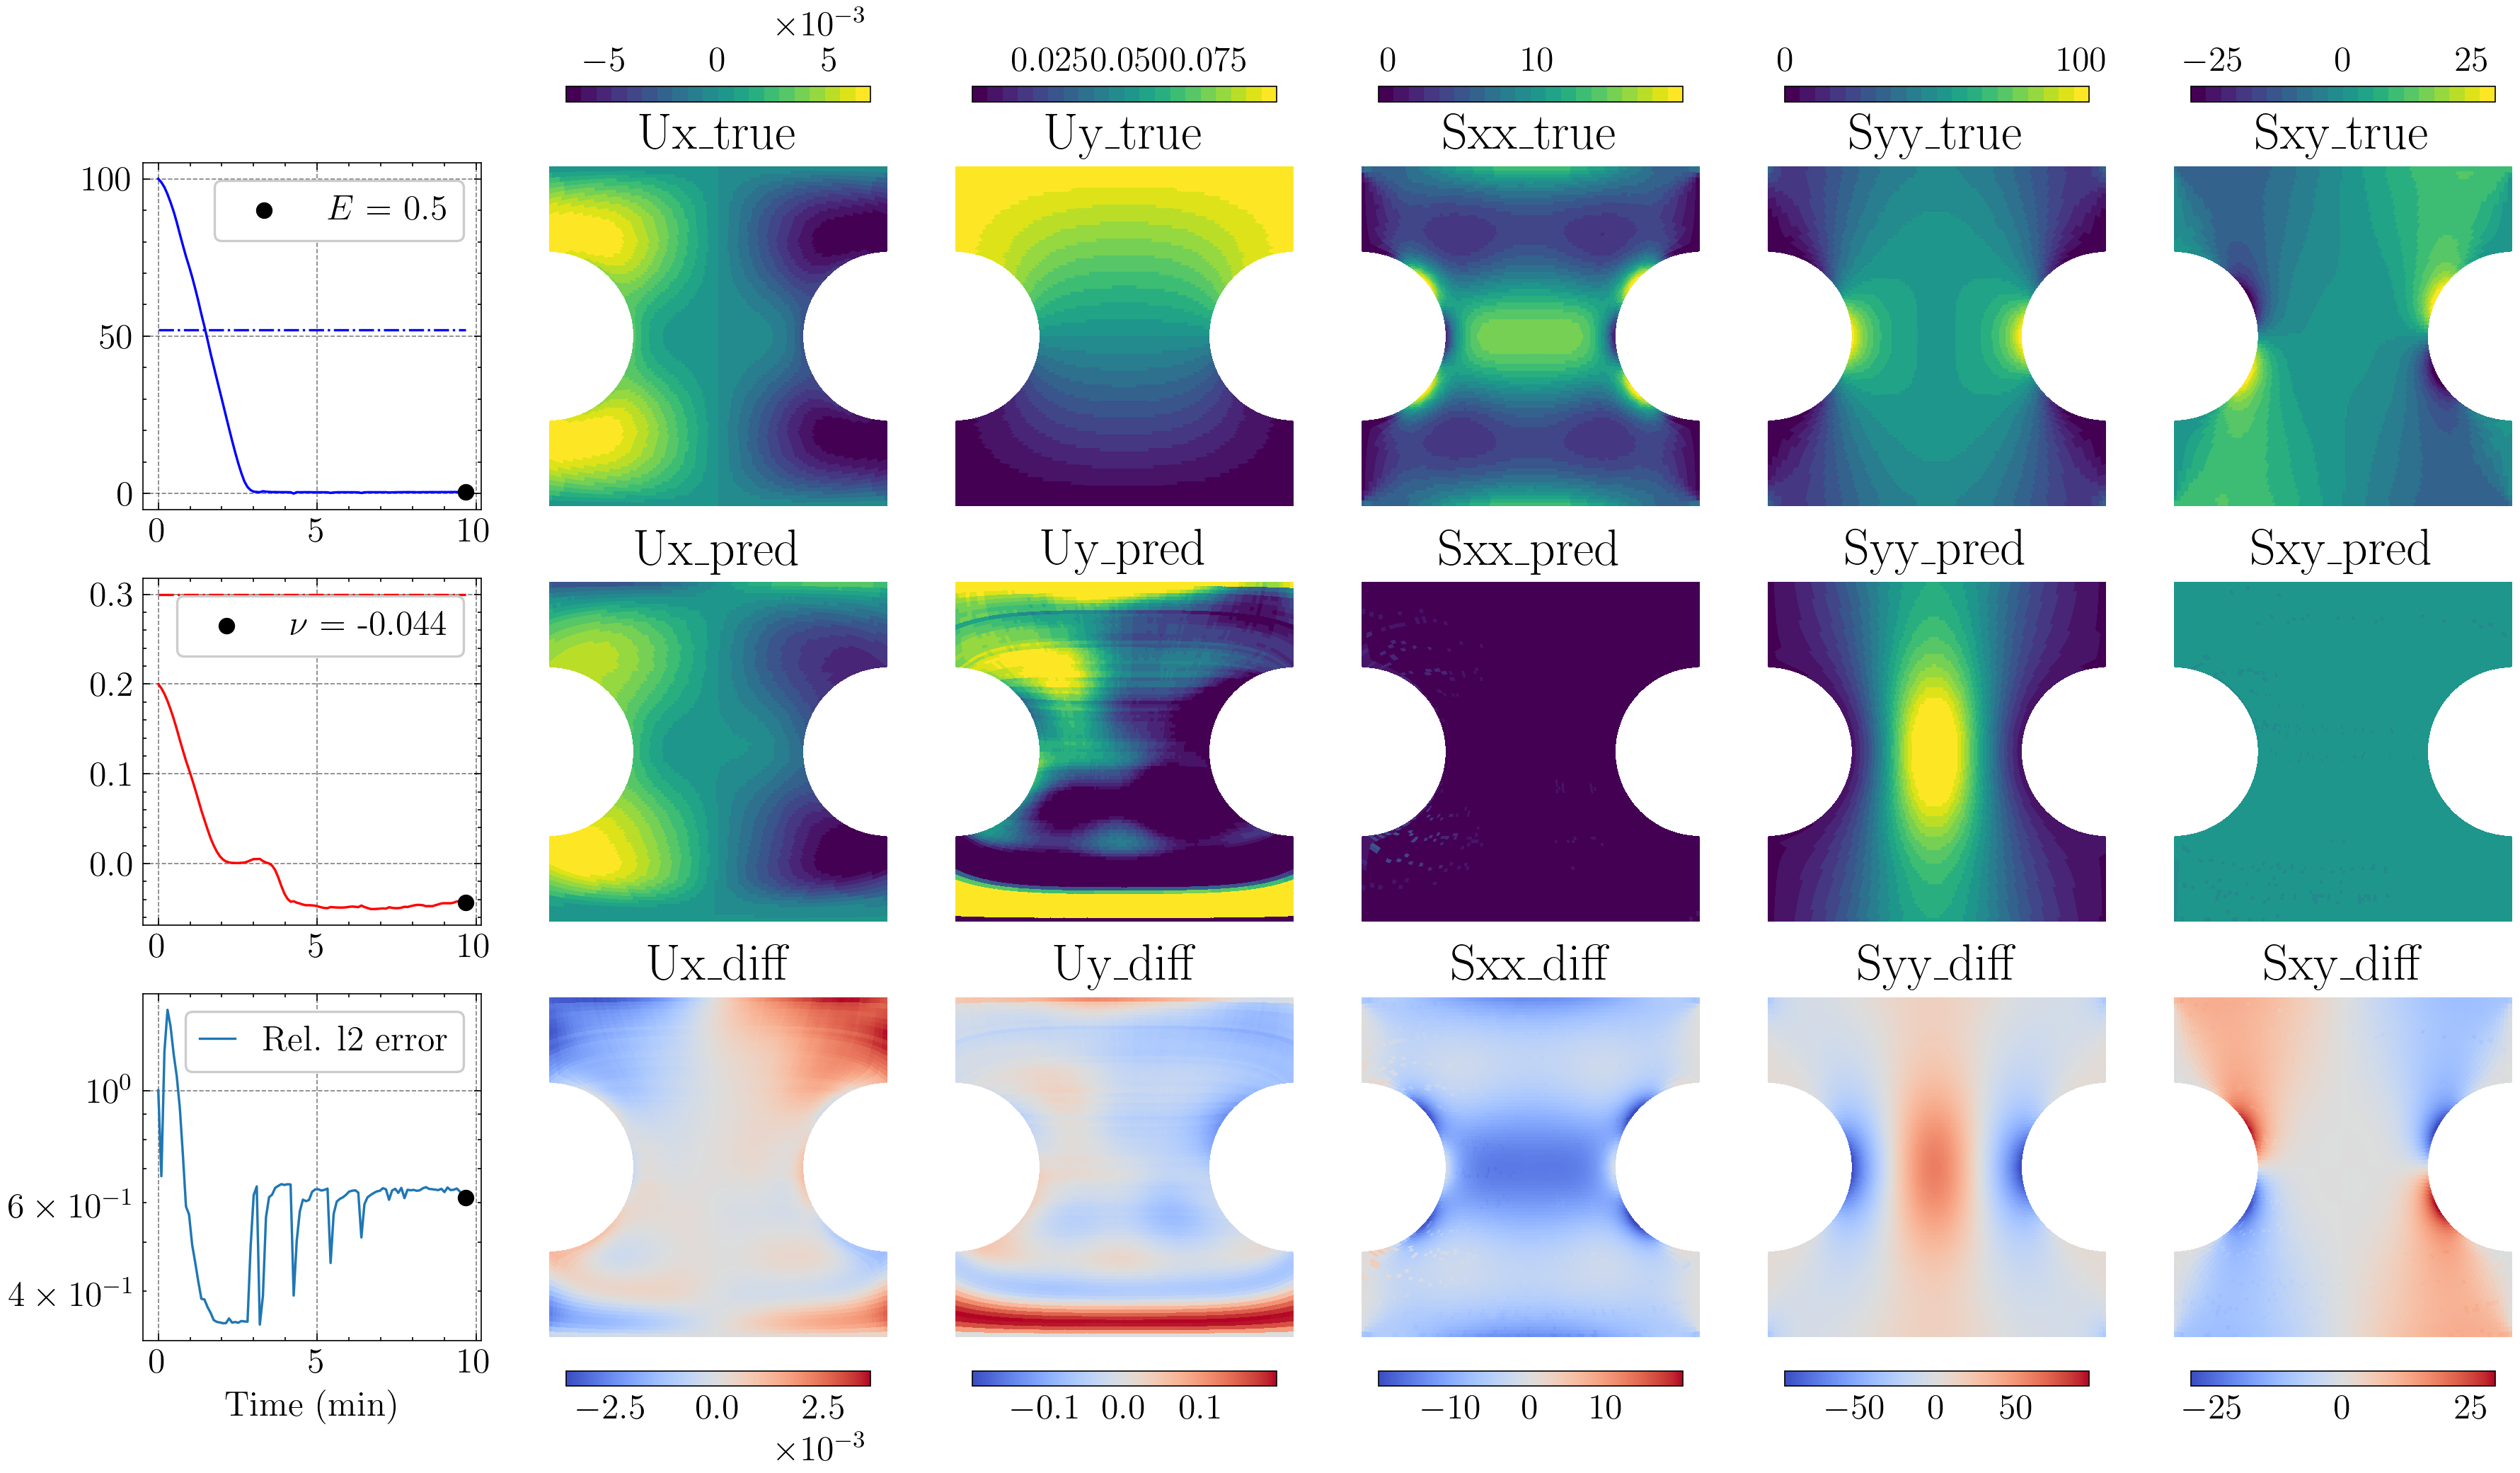

In [18]:
# Field Plotting
import matplotlib.colors as mcolors
from scipy.interpolate import RegularGridInterpolator

# --- Font size for printing ---
plotting_factor = 3
font_factor = 3
title_font_size = 6
axes_font_size = 5
plt.rcParams.update({
    "font.size": title_font_size*font_factor,         # Default font size for all text
    "figure.titlesize": title_font_size*font_factor, 
    "axes.labelsize": axes_font_size*font_factor,
    "xtick.labelsize": axes_font_size*font_factor,
    "ytick.labelsize": axes_font_size*font_factor,
    "legend.fontsize": axes_font_size*font_factor,
})

plot_metrics = 1 # 1 to plot metrics, 0 to not plot metrics
fields_plotted = [0,1,2,3,4,5,6,7][:] #{0: "Ux", 1: "Uy", 2: "Sxx", 3: "Syy", 4: "Sxy"}
fields_plotted = [0, 1, 2, 3, 4, 5, 6, 7][:2] + [0, 1, 2, 3, 4, 5, 6, 7][5:]  # Select all fields except [2, 3, 4]

n_fields = len(fields_plotted)

# --- Custom colormap ---
cmap = plt.get_cmap('viridis')
num_colors = 20
color_values = [cmap(i) for i in np.linspace(0, 1, num_colors)]
cmap = mcolors.ListedColormap(color_values)

# --- Load FEM reference solution and create interpolators ---
n_rows = 100
n_cols = 100
material_law = run_config["problem"]["material_law"]
L_max = int(run_config["problem"]["x_max"])  # in mm
FEM_dataset = f"{material_law}_{n_rows}x{n_cols}.dat"
fem_file = os.path.join("../data_fem", FEM_dataset)

data = np.loadtxt(fem_file)
X_val = data[:, :2]
u_val = data[:, 2:4]
strain_val = data[:, 4:7]
stress_val = data[:, 7:10]
solution_val = np.hstack((u_val, strain_val, stress_val))
n_mesh_points = int(np.sqrt(X_val.shape[0]))
x_grid = np.linspace(0, L_max, n_mesh_points)
y_grid = np.linspace(0, L_max, n_mesh_points)
interpolators = [RegularGridInterpolator((x_grid, y_grid),
                                          solution_val[:, i].reshape(n_mesh_points, n_mesh_points).T)
                 for i in range(solution_val.shape[1])]
func = lambda x: np.array([interp((x[:, 0], x[:, 1])) for interp in interpolators]).T

# --- Prepare a square grid for field plotting ---

nx=60
ny=88
Xp = np.loadtxt(f"../deep_notched_{nx}x{ny}.txt")

# Interpolate mapping
X_map_points = Xp[:, 0].reshape((ny, nx)).T
Y_map_points = Xp[:, 1].reshape((ny, nx)).T

def coordMap(x, X_map = X_map_points, Y_map = Y_map_points, x_max = L_max, y_max=L_max, padding=1e-6):
    x_pos = x[0] / x_max * (X_map.shape[0]-1) * (1-2*padding) + padding
    y_pos = x[1] / y_max * (Y_map.shape[1]-1) * (1-2*padding) + padding
    xm = jax.scipy.ndimage.map_coordinates(X_map,
           [x_pos, y_pos], order=1, mode='nearest')
    ym = jax.scipy.ndimage.map_coordinates(Y_map,
           [x_pos, y_pos], order=1, mode='nearest')
    return jnp.stack([xm, ym])

ngrid = 100

x_edge = np.linspace(0, L_max, ngrid+1)
y_edge = np.linspace(0, L_max, ngrid+1)
Xedge, Yedge = np.meshgrid(x_edge, y_edge, indexing="ij")
Xgrid = jax.vmap(coordMap)(np.stack((Xedge.ravel(), Yedge.ravel()), axis=1))
Xmesh, Ymesh = Xgrid[:,0].reshape(Xedge.shape), Xgrid[:,1].reshape(Yedge.shape)

# Center coordinates (for evaluating fields)
x_center = 0.5 * (x_edge[:-1] + x_edge[1:])
y_center = 0.5 * (y_edge[:-1] + y_edge[1:])
# Xgrid, Ygrid = jax.vmap(coordMap)(np.stack((Xc.ravel(), Yc.ravel()), axis=1))
Xgrid, Ygrid = np.meshgrid(x_center, y_center, indexing="ij")

# --- Plotting ---
subplot_width = plotting_factor
fig, ax = plt.subplots(3,plot_metrics+n_fields,figsize = (plot_metrics*subplot_width+n_fields*subplot_width,subplot_width*3),dpi = 40*plot_metrics+40*n_fields)
printed_font_size = 6
title_font_size = plt.rcParams['font.size']
axes_font_size = ax[0][0].get_xticklabels()[0].get_fontsize()
print(f"Fig width: {fig.get_figwidth()}, set it to {fig.get_figwidth()*printed_font_size/title_font_size:.2f} < 6.34 (A4 with margins) in latex to have a printed font size of {printed_font_size} for titles and {axes_font_size*printed_font_size/title_font_size:.2f} for the axis")


iteration = len(steps) - 1
# Plot parameter evolution on ax_var1 and ax_var2 using functions from plot_util
if plot_metrics:
    axs_var = [ax[0][0], ax[1][0]]
    line_E, line_nu, scatter_E, scatter_nu, ax_variables = init_variables(
        axs_var,
        steps, E_actual, nu_actual, E_history, nu_history,
        E_name, nu_name
    )
    update_variables(iteration, line_E, line_nu, scatter_E, scatter_nu,
                    axs_var,
                    steps, E_history, nu_history,
                    E_actual, nu_actual, E_name, nu_name)

    # Plot metrics on ax_metric
    lines, scatters = init_metrics(ax[2][0], steps, metrics, metrics_names, 
                                step_type=step_type, time_unit=time_unit, metrics_idx=[0])
    update_metrics(iteration, lines, scatters, steps, metrics, metrics_idx=[0])

ims_field = []
ims_ref = []
ims_res = []
ax_fields = ax[:, plot_metrics:]
ims_ref, ims_field, ims_res = plot_field_columns(fig, ax_fields, fields, fields_plotted, iteration,
                                                  Xmesh, Ymesh, Xgrid, Ygrid, func, field_names, cmap, make_formatter)

plt.tight_layout
plt.show()

In [ ]:
# Save figure
fig_name = f"{run}_"+ "_".join([field_names[fid] for fid in fields_plotted])
fig.savefig(f'./{fig_name}.png', dpi=500, bbox_inches='tight')

In [8]:
def animate_frame(i, ims_field, ims_res,
                  lines, scatters, steps, time_unit, step_type, metrics, fields, func, Xgrid, Ygrid, field_names, fields_id):

    plt.suptitle(f"{step_type}: {steps[i]:.0f}{f' {time_unit}' if step_type=='time' else ''}", fontsize=16)
    
    # Update metric plots
    lines, scatters = update_metrics(i, lines, scatters, steps, metrics)
    
    # Update field and residual plots for each field
    # Update field and residual plots for each field
    for idx, fid in enumerate(fields_id):
        field = np.array(fields[fid][i]).reshape(Xgrid.shape)
        field_exact = func(np.hstack((Xgrid.reshape(-1, 1), Ygrid.reshape(-1, 1))))[:, fid].reshape(Xgrid.shape)
        field_diff = field - field_exact
        
        ims_field[idx].set_array(field.ravel())
        ims_res[idx].set_array(field_diff.ravel())
        norm =  mcolors.Normalize(vmin=field_diff.min(), vmax=field_diff.max())
        ims_res[idx].set_norm(norm)
    
    return ims_field, ims_res, lines, scatters

In [9]:
# Animation
import matplotlib.animation as animation
from IPython.display import HTML

# Add time to the title
fig.suptitle(f"{step_type}: {steps[iteration]:.0f}{f'{time_unit}' if step_type == 'time' else ''}", fontsize=20, y=1)

# Prepare a list of frame indices (subsample if desired)
all_steps = list(range(len(steps)))
sub_factors = [1]#[1,2] + [3]*3  # Adjust subsampling factors as needed
frame_steps = list(subsample_steps(all_steps, sub_factors))

# Reuse the figure from Cell 4 (or create a new one if preferred)
anim = animation.FuncAnimation(
    fig,
    animate_frame,
    frames=frame_steps,
    fargs=(ims_field, ims_res, lines, scatters, steps, time_unit, step_type, metrics, fields, func, Xgrid, Ygrid, field_names, fields_plotted),
    interval=100,
    repeat=False
)

fps = 10
print("Video duration: ", len(frame_steps)/fps, "s")
# HTML(anim.to_jshtml())

Video duration:  10.3 s


In [10]:
# Save video
fig_name = f"{run}_"+ "_".join([field_names[fid] for fid in fields_plotted]) 
extension = ".mp4"  # or ".gif"
video_name = f"{fig_name}_{step_type}{extension}"
anim.save(video_name, writer='ffmpeg', fps=fps)

print(f"Video saved at {video_name}")

Video saved at isotropic_100x100_0.0noise_101000iter-1_Ux_Uy_Sxx_Syy_Sxy_time.mp4


<Figure size 350x262.5 with 0 Axes>